# Rent 09 · Build the project: one row per building
**Know Before You Rent · Team BUTA**

This notebook turns the cleaned datasets into the table the model learns from. **One row = one residential building with 3+ apartments.**

| Feature group | Examples | Answers |
|---|---|---|
| Building traits | age, era, apartments, floors, elevator vs walk-up | Q3 |
| Own history (previous 2 years) | complaints per problem type, violations by class (A/B/C), bedbugs, evictions | Q1 |
| Landlord record | the landlord's **other** buildings' complaint rate per type (leave-one-out) | Q2 |
| 100 m around it | complaints per type in other buildings within 100 m | Q4 |
| **Targets** | `y_<type>` = 1 if the building gets that complaint type **next year** | Q5 |

**Time split, with no peeking into the future:**
- **Train:** history 2022–23 → predict 2024.
- **Test:** history 2023–24 → predict 2025.

Code: `src/features_housing.py`.

In [1]:
import sys, pathlib
ROOT = pathlib.Path.cwd().parent if pathlib.Path.cwd().name == "notebooks" else pathlib.Path.cwd()
sys.path.insert(0, str(ROOT))

import pandas as pd, numpy as np, matplotlib.pyplot as plt
from src import features_housing as F
from src.plots import save, ACCENT, MUTED

pd.set_option("display.float_format", "{:,.3f}".format)
inp = F.load_inputs()
universe = F.building_universe(inp["pluto"], inp["landlords"])
print(f"Buildings (3+ apartments): {len(universe):,} | apartments: {universe.unitsres.sum():,.0f} | "
      f"registered with HPD: {universe.is_registered.mean():.1%}")

Buildings (3+ apartments): 172,546 | apartments: 2,870,343 | registered with HPD: 80.8%


## 1. The 100 m neighborhood graph

In [2]:
A = F.neighbor_matrix(universe)
deg = np.asarray(A.sum(axis=1)).ravel()
print(f"Building pairs within {F.NEIGHBOR_RADIUS_M} m: {A.nnz // 2:,} | median neighbors per building: {np.median(deg):.0f}")

Building pairs within 100 m: 2,773,744 | median neighbors per building: 30


## 2. Build the train (2024) and test (2025) tables

In [3]:
train = F.build_snapshot(2024, inp, universe, A)
test = F.build_snapshot(2025, inp, universe, A)
for df in (train, test):
    df.to_parquet(str(F.FEATURES_FILE).format(year=int(df.target_year.iat[0])), index=False)
print("train", train.shape, "| test", test.shape, "| features:", len(F.feature_columns(train)))
train.head(3).T.head(45)

train (172546, 65) | test (172546, 65) | features: 47


,0,1,2
bbl,1000050010,1000070038,1000077501
borough,MANHATTAN,MANHATTAN,MANHATTAN
zipcode,10004,10004,10004
latitude,40.703,40.703,40.703
longitude,-74.011,-74.011,-74.011
yearbuilt,"1,969.000","1,830.000","1,880.000"
building_age,56.000,195.000,145.000
era,1960-79,<1920,<1920
unitsres,"1,320.000",3.000,42.000
numfloors,32.000,5.000,6.000


In [4]:
# How common is each problem next year? (the base rate the model must beat)
pd.DataFrame({"2024": train[F.target_columns()].mean(), "2025": test[F.target_columns()].mean()}).mul(100).round(1) \
    .rename(index=lambda s: s[2:]).rename_axis("% of buildings with ≥1 complaint")

,2024,2025
% of buildings with ≥1 complaint,,
heat_hot_water,15.400,16.800
pests,9.000,8.900
leaks_mold,10.900,10.400
plumbing,9.200,9.500
paint_plaster,8.900,8.500
doors_windows,8.100,8.000
safety,3.800,3.800


## 3. First answers, before any model
Each table shows the share of buildings that got that problem in **2024**, split by one factor measured in **2022–23**.

### Q1: does a building's history predict its future?

In [5]:
rows = []
for t in F.TARGET_TYPES:
    s = F.slug(t)
    had = train[f"c_{s}"] > 0
    rows.append({"problem": t, "had it in 2022-23": train.loc[had, f"y_{s}"].mean(),
                 "didn't": train.loc[~had, f"y_{s}"].mean()})
q1 = pd.DataFrame(rows).set_index("problem")
q1["× more likely"] = q1.iloc[:, 0] / q1.iloc[:, 1]
q1

,had it in 2022-23,didn't,× more likely
problem,,,
heat/hot water,0.547,0.050,10.915
pests,0.459,0.036,12.676
leaks/mold,0.507,0.040,12.580
plumbing,0.467,0.036,12.859
paint/plaster,0.497,0.033,14.991
doors/windows,0.463,0.032,14.419
safety,0.272,0.023,11.839


### Q2: does the landlord matter?
Buildings with a multi-building landlord, split by how their landlord's **other** buildings did (quartiles of the leave-one-out rate).

In [6]:
port = train[train.has_portfolio]
rows = {}
for t in F.TARGET_TYPES:
    s = F.slug(t)
    q = pd.qcut(port[f"ll_rate_{s}"].rank(method="first"), 4, labels=["best 25%", "Q2", "Q3", "worst 25%"])
    rows[t] = port.groupby(q, observed=True)[f"y_{s}"].mean()
q2 = pd.DataFrame(rows).T
q2["worst ÷ best"] = q2["worst 25%"] / q2["best 25%"]
print(f"Buildings with a multi-building landlord: {len(port):,} ({len(port) / len(train):.0%})")
q2

Buildings with a multi-building landlord: 57,106 (33%)


,best 25%,Q2,Q3,worst 25%,worst ÷ best
heat/hot water,0.101,0.208,0.384,0.552,5.436
pests,0.064,0.092,0.220,0.370,5.745
leaks/mold,0.072,0.130,0.281,0.440,6.089
plumbing,0.064,0.100,0.233,0.390,6.088
paint/plaster,0.060,0.081,0.216,0.405,6.781
doors/windows,0.057,0.072,0.208,0.348,6.076
safety,0.034,0.034,0.088,0.154,4.500


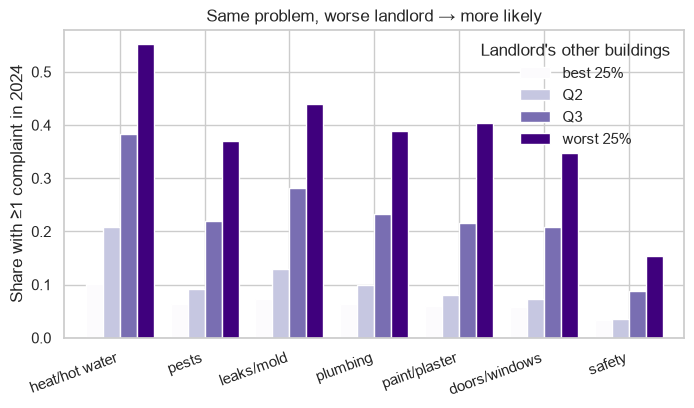

In [7]:
fig, ax = plt.subplots(figsize=(8, 4))
q2.drop(columns="worst ÷ best").plot(kind="bar", ax=ax, colormap="Purples", width=0.8)
ax.set(ylabel="Share with ≥1 complaint in 2024", xlabel="", title="Same problem, worse landlord → more likely")
ax.legend(title="Landlord's other buildings", frameon=False)
plt.xticks(rotation=20, ha="right")
save(fig, "rent09a_landlord_effect")

### Q3: building age and type

In [8]:
train.groupby("era")[F.target_columns()].mean().rename(columns=lambda s: s[2:]).loc[
    ["<1920", "1920-39", "1940-59", "1960-79", "1980-99", "2000+"]].mul(100).round(1)

,heat_hot_water,pests,leaks_mold,plumbing,paint_plaster,doors_windows,safety
era,,,,,,,
<1920,14.800,8.200,9.600,8.400,7.900,7.400,3.400
1920-39,19.000,11.300,13.400,11.400,11.500,10.300,4.900
1940-59,18.700,11.000,13.900,11.200,11.700,9.200,4.300
1960-79,10.200,6.200,7.600,6.400,6.100,5.400,2.400
1980-99,8.100,4.900,6.000,5.100,3.900,3.700,1.700
2000+,11.400,6.500,9.000,7.400,6.100,5.900,2.800


In [9]:
kind = np.select([train.is_elevator, train.is_walkup], ["elevator", "walk-up"], "other")
train.groupby(kind)[F.target_columns()].mean().rename(columns=lambda s: s[2:]).mul(100).round(1)

,heat_hot_water,pests,leaks_mold,plumbing,paint_plaster,doors_windows,safety
elevator,48.600,30.000,37.300,32.100,31.600,27.400,12.600
other,10.200,4.900,6.300,5.400,4.400,4.200,2.200
walk-up,12.500,7.200,8.500,7.200,7.000,6.400,3.000


### Q4: does the 100 m neighborhood add information?
Only buildings **without** that problem in their own history, so the neighborhood is the only signal.

In [10]:
rows = {}
for t in F.TARGET_TYPES:
    s = F.slug(t)
    clean_hist = train[train[f"c_{s}"] == 0]
    nb = pd.qcut(clean_hist[f"nb100_{s}"].rank(method="first"), 4, labels=["quietest 25%", "Q2", "Q3", "busiest 25%"])
    rows[t] = clean_hist.groupby(nb, observed=True)[f"y_{s}"].mean()
q4 = pd.DataFrame(rows).T
q4["busiest ÷ quietest"] = q4["busiest 25%"] / q4["quietest 25%"]
q4

,quietest 25%,Q2,Q3,busiest 25%,busiest ÷ quietest
heat/hot water,0.025,0.032,0.053,0.090,3.588
pests,0.016,0.025,0.036,0.068,4.177
leaks/mold,0.020,0.028,0.041,0.072,3.617
plumbing,0.018,0.025,0.035,0.067,3.734
paint/plaster,0.015,0.022,0.033,0.062,4.138
doors/windows,0.014,0.021,0.032,0.061,4.269
safety,0.014,0.014,0.023,0.041,3.009


## 4. What we have
- Train and test tables are saved to `data/processed/building_features_2024.parquet` and `building_features_2025.parquet`.
- The tables above give **descriptive** answers to Q1–Q4.

The next notebook trains a model per problem type (Q5). It measures how much each feature group adds, and is tested on 2025, a year the model never saw.